In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
import sys
import yaml
from pathlib import Path
from tqdm.auto import tqdm
from joblib import Parallel, delayed
from scipy.spatial.distance import hamming

# make figures paper quality
import matplotlib
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
# matplotlib.rcParams['font.family'] = 'Arial'

import warnings
warnings.filterwarnings("ignore")

/home/peidli/miniconda3/envs/sc_env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [127]:
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)

seq_primer = config['primer_seq']  # sequence left of gRNA
guide_length = config['guide_length']
# primer will appear between min and max position
pmin, pmax = config['primer_range']['min'], config['primer_range']['max']

path = Path(config['TEMPDIR']) / 'pooled_screen_1/fastq'

In [128]:
cell_line_dict={
    '01': 'H1975',
    '02': 'H1299',
    '03': 'A549'
}

# Target Alignment

In [48]:
def parse_sam_file(sam_file):
    data = []
    with open(sam_file, 'r') as f:
        for line in f:
            # Skip header lines if any
            if line.startswith('@'):
                continue
            
            fields = line.strip().split('\t')
            # Extract relevant fields
            query_name = fields[0]
            flag = int(fields[1])
            reference_name = fields[2]
            position = int(fields[3])
            mapq = int(fields[4])
            cigar = fields[5]
            rnext = fields[6]
            pnext = int(fields[7])
            tlen = int(fields[8])
            seq = fields[9]
            qual = fields[10]
            # Additional optional fields
            optional_fields = fields[11:]
            # Store the information
            data.append({'QueryName': query_name, 'Flag': flag, 'ReferenceName': reference_name, 'Position': position,
                         'MappingQuality': mapq, 'CIGAR': cigar, 'RNext': rnext, 'PNext': pnext, 'TLEN': tlen,
                         'Sequence': seq, 'Quality': qual, 'OptionalFields': optional_fields})
    return data

In [56]:
data_path = "/scratch/peidli/SYMPHONY/pooled_screen_1/bwa/pooled_screen_1_guides_to_genome.sam"
data_path = "/scratch/peidli/SYMPHONY/pooled_screen_1/hisat2/guides_aligned_to_genome.sam"

In [98]:
# 16 (0x10): This flag indicates that the read is mapped to the reverse strand. In binary, 16 is represented as 10000, with the fifth bit set to 1.

# 0 (0x0): This flag indicates that none of the optional flags are set. In binary, 0 is represented as 00000, indicating that none of the flags are set.

# 272 (0x110): This flag indicates that the read is properly aligned according to the aligner. This flag is a combination of two flags:

# 256 (0x100): This flag indicates that the read is a primary alignment (not a secondary alignment or supplementary alignment).
# 16 (0x10): As mentioned earlier, this flag indicates that the read is mapped to the reverse strand.

# 4 (0x4): This flag indicates that the read is unmapped. In binary, 4 is represented as 00100, with the third bit set to 1.

In [114]:
alignment = pd.DataFrame(parse_sam_file(data_path)).set_index('QueryName')

In [115]:
alignment['strand'] = None
alignment['strand'][(alignment['Flag'] == 16) | (alignment['Flag'] == 272)] = '-'
alignment['strand'][(alignment['Flag'] == 0) | (alignment['Flag'] == 256)] = '+'
alignment.drop(['RNext', 'PNext', 'TLEN', 'OptionalFields'], inplace=True, axis=1)
alignment.rename(columns={'ReferenceName': 'chromosome', 'Position': 'Start_position'}, inplace=True)
alignment.index.name = 'guide_id'
alignment['End_position'] = alignment['Start_position'] + alignment['Sequence'].str.len()
alignment = alignment[alignment.MappingQuality > 30]

In [116]:
alignment

,Flag,chromosome,Start_position,MappingQuality,CIGAR,Sequence,Quality,strand,End_position
guide_id,,,,,,,,,
CYP26B1_ENST00000001146_2702,0,2,72131268,60,23M,TTAAACCCAAATAATGCCCGGAG,IIIIIIIIIIIIIIIIIIIIIII,+,72131291
RPS20_ENST00000009589_544,0,8,56073029,60,23M,TATTCTGAATAAAAACCAACAGA,IIIIIIIIIIIIIIIIIIIIIII,+,56073052
NDUFAB1_ENST00000007516_654,0,16,23581065,60,23M,AAGTCCATCAGAATCACTCTGTC,IIIIIIIIIIIIIIIIIIIIIII,+,23581088
COX15_ENST00000016171_2286,0,10,99713585,60,23M,ATTACAAAGCTGTTAGGAAACCC,IIIIIIIIIIIIIIIIIIIIIII,+,99713608
AQR_ENST00000156471_5156,0,15,34856320,60,23M,AATATCTTTACATAAAGACAGCA,IIIIIIIIIIIIIIIIIIIIIII,+,34856343
...,...,...,...,...,...,...,...,...,...
AFAP1-AS1_ENST00000608442_4117,16,4,7776228,60,23M,GGTGGCATAATGATTAAGAATAA,IIIIIIIIIIIIIIIIIIIIIII,-,7776251
AFAP1-AS1_ENST00000608442_5002,16,4,7777113,60,23M,CGTGGGACTCCGATTTTGCTTGT,IIIIIIIIIIIIIIIIIIIIIII,-,7777136
AFAP1-AS1_ENST00000608442_3741,16,4,7775852,60,23M,GGGCAACACATAAATGCTTATTT,IIIIIIIIIIIIIIIIIIIIIII,-,7775875


In [118]:
guide_df = pd.read_csv('../resources/all_gRNA_data.csv', index_col='unique_guide_name')

In [119]:
guide_df

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,gRNA_occurence,transcript_per_gene
unique_guide_name,,,,,,,,,,,,
CYP26B1_ENST00000001146_2702,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA2661:2680-2702,TTAAACCCAAATAATGCCCGGAG,2702.0,1.306530,UTR3,4556.0,1,2
CYP26B1_ENST00000001146_4708,ENST00000001146,ENSG00000003137,CYP26B1,protein_coding,crRNA4464:4686-4708,AAGCCTATAGAAGAGCCACATTG,4708.0,1.411459,UTR3,4556.0,1,2
NDUFAB1_ENST00000007516_654,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA632:632-654,AAGTCCATCAGAATCACTCTGTC,654.0,1.012291,UTR3,665.0,1,1
NDUFAB1_ENST00000007516_667,ENST00000007516,ENSG00000004779,NDUFAB1,protein_coding,crRNA645:645-667,ACAATTTAAATACAAGTCCATCA,667.0,0.996597,UTR3,665.0,1,1
RPS20_ENST00000009589_568,ENST00000009589,ENSG00000008988,RPS20,protein_coding,crRNA508:546-568,CTTTATATTCCTAAAATCTGCCA,568.0,0.821865,UTR3,519.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...
NT_Control_rc_000400_NA,rc_000400,NaN,NT_Control,NT_Control,rc_000400,ATCTCGTCGTGCTTTATTATAGT,NaN,NaN,NaN,NaN,1,100
NT_Control_rc_001028_NA,rc_001028,NaN,NT_Control,NT_Control,rc_001028,GCGACTACGGTGTATGCATTCCA,NaN,NaN,NaN,NaN,1,100
NT_Control_rc_001002_NA,rc_001002,NaN,NT_Control,NT_Control,rc_001002,GATACGAAGCCAACTCTTGCGCT,NaN,NaN,NaN,NaN,1,100


In [122]:
tab = pd.merge(guide_df, alignment, left_index=True, right_index=True, how='left')

In [123]:
tab.to_csv('../resources/guide_alignment_dna_v0.csv')

# Counts per guide

In [131]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
# df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

In [132]:
# the lowest we ever detect any guide in Pools is 217
gmin = df.loc[:, pools].min(1).min()

In [133]:
df_ = df.loc[:, pools].min(1).reset_index()
df_['NT guide'] = df.index.isin(controls)

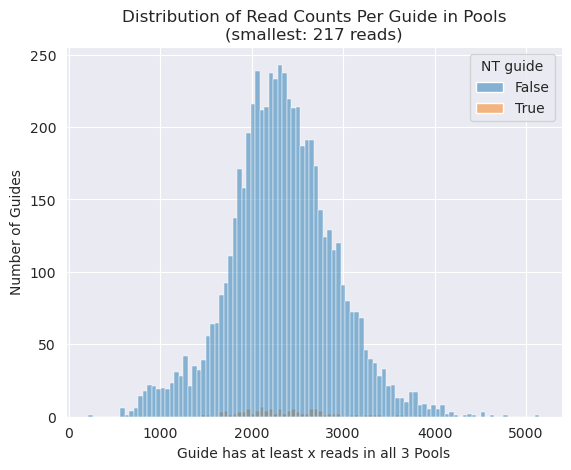

In [134]:
with sns.axes_style('darkgrid'):
    sns.histplot(df_, x=0, bins=100, hue='NT guide')
pl.xlabel('Guide has at least x reads in all 3 Pools')
pl.ylabel('Number of Guides')
pl.title(f'Distribution of Read Counts Per Guide in Pools\n(smallest: {gmin} reads)')
pl.savefig('../results/figures/hist_read_counts_per_guide.pdf', bbox_inches='tight')
pl.show()

# Counts

In [4]:
# df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

In [6]:
df.head()

,Transcript_ID,ensembl_gene_id,Gene,transcript_biotype,GuideName,GuideSeq,MatchPos,Guide_Score,Region,transcript_length,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
AATBC_ENST00000400385_1005,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0983:983-1005,ACAGAACCCTAGGAAGCAACCTC,1005.0,0.789626,Gene_Body,4598.0,...,1235,1494,1747,1655,1494,1545,1298,1842,1277,1391
AATBC_ENST00000400385_1562,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1504:1540-1562,CCAGGCCACTTGCTCCACCCTCT,1562.0,0.747814,Gene_Body,4598.0,...,1885,2072,2450,2161,2318,2164,1775,2276,1863,2168
AATBC_ENST00000400385_1938,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA1862:1916-1938,TGACCTCTCACCCCGCAGCCTCT,1938.0,0.747682,Gene_Body,4598.0,...,1199,1299,1680,1402,1473,1463,1166,1650,1139,1391
AATBC_ENST00000400385_2713,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA2601:2691-2713,CTGCCTTATAAAGATAGACCGGT,2713.0,0.870540,Gene_Body,4598.0,...,799,1175,1268,1071,1026,1157,892,1263,835,1073
AATBC_ENST00000400385_28,ENST00000400385,ENSG00000215458,AATBC,lncRNA,crRNA0006:6-28,CCGGTCTCTGCAGTCACCCTCCT,28.0,0.762563,Gene_Body,4598.0,...,1518,1898,2201,1797,1975,2039,1678,2248,1576,1842


In [7]:
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1' 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

## Normalization

In [180]:
# I think median control normalization seems best

In [181]:
# Seq Depth Normalization
n_counts = df[sample_names].sum()
df_depth = df[sample_names] / n_counts * np.median(n_counts)

In [182]:
# Median norm with control guides
median_counts_control = df.loc[controls, sample_names].median()
df_medctrl = df[sample_names] / median_counts_control

<Axes: ylabel='unique_guide_name'>

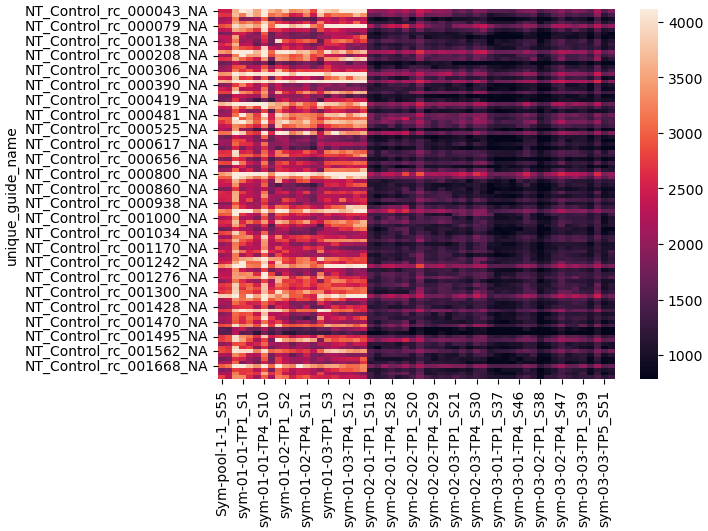

In [183]:
# control raw
sns.heatmap(df.loc[controls, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

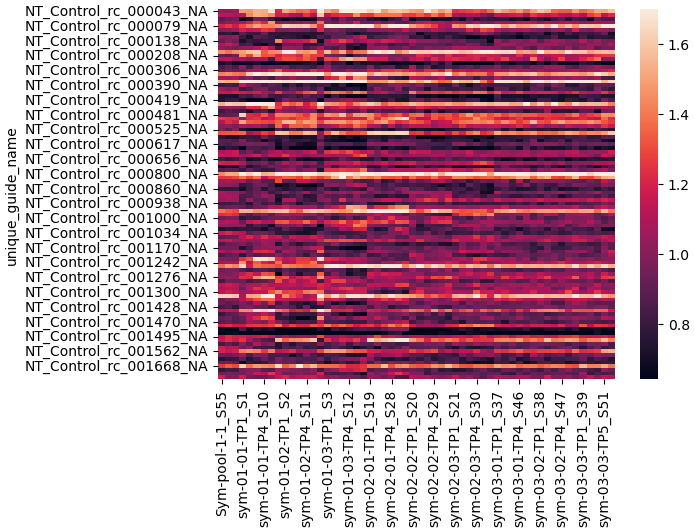

In [184]:
# control after median normalization
sns.heatmap(df_medctrl.loc[controls, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

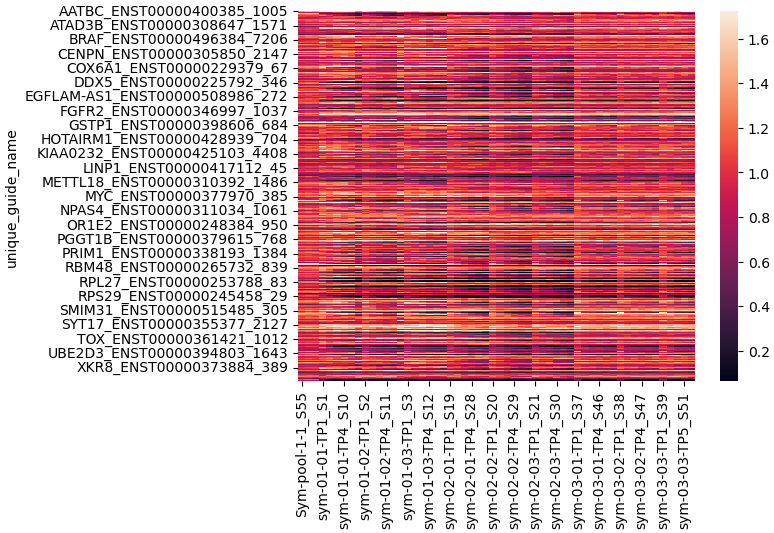

In [185]:
# all after median normalization
sns.heatmap(df_medctrl.loc[:, sample_names], robust=True)

<Axes: ylabel='unique_guide_name'>

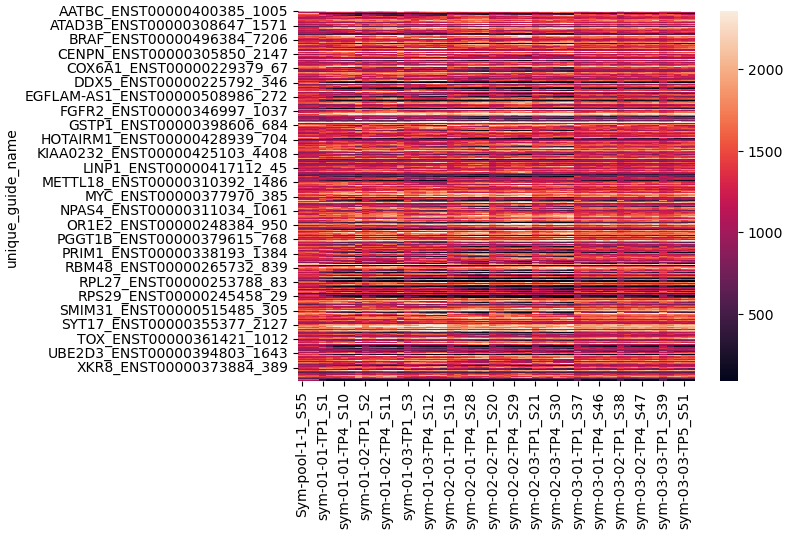

In [186]:
# all after depth normalization
sns.heatmap(df_depth.loc[:, sample_names], robust=True)

## Big heatmap

In [8]:
# Median norm with control guides
median_counts_control = df.loc[controls, sample_names].median()
fc = df[sample_names] / median_counts_control
l2fc = np.log2(fc)

In [12]:
l2fc[l2fc==-np.infty] = None

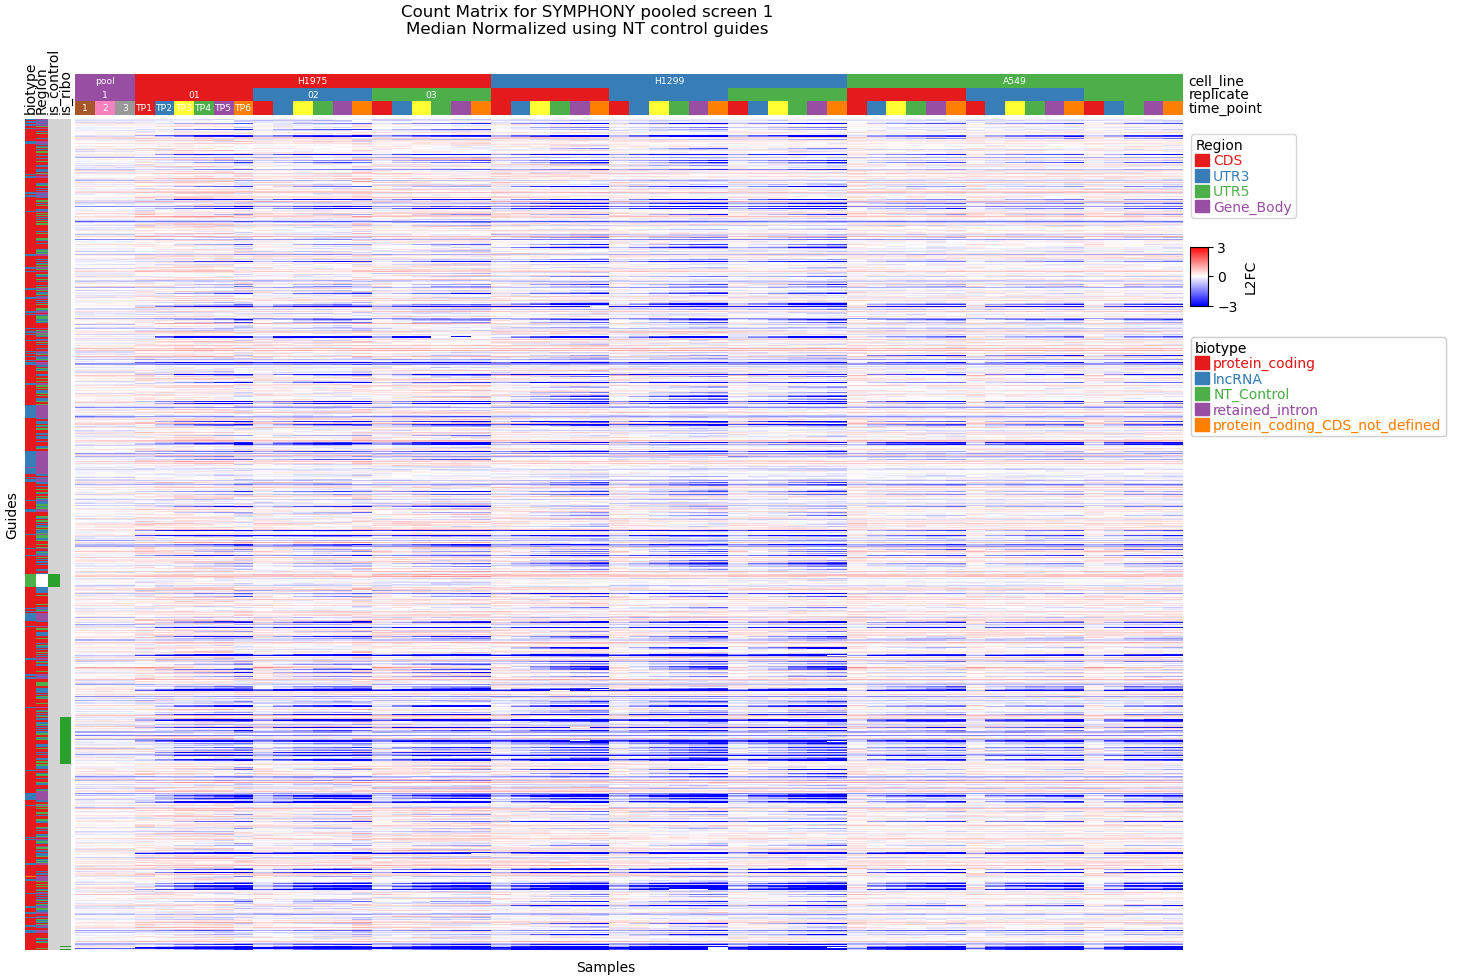

In [16]:
import PyComplexHeatmap as pch
data = l2fc.loc[:, sample_names]

cell_line = pd.Series({x: x.split('-')[1] for x in data.columns}).replace(cell_line_dict)
replicate = pd.Series({x: x.split('-')[2] for x in data.columns})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] for x in data.columns})

top_ha = pch.HeatmapAnnotation(
    cell_line=pch.anno_simple(cell_line, add_text=True),
    replicate=pch.anno_simple(replicate, add_text=True),
    time_point=pch.anno_simple(time_point, add_text=True),
    verbose=0, axis=1, plot_legend=False
)

is_control = pd.Series(np.array(['control' in x.lower() for x in df.index], dtype=str), index=df.index)
is_ribo = pd.Series(np.array([(x[:3]=='RPS') or (x[:3]=='RPL') for x in df.index], dtype=str), index=df.index)

left_ha = pch.HeatmapAnnotation(
    biotype=pch.anno_simple(df['transcript_biotype'], legend=True),
    Region=pch.anno_simple(df['Region'], legend=True),
    is_control=pch.anno_simple(is_control, colors={'False': 'lightgrey', 'True': 'tab:green'}, legend=False),
    is_ribo=pch.anno_simple(is_ribo, colors={'False': 'lightgrey', 'True': 'tab:green'}, legend=False),
    verbose=0, axis=0, plot_legend=True
)

pl.figure(figsize=(15, 10))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, legend_gap=7,
    rasterized=True, cmap='bwr', vmin=-3, vmax=3,
    legend_kws=dict(label='L2FC'),
    xlabel="Samples", ylabel='Guides', legend_hpad=0,
    verbose=0
)
pl.suptitle('Count Matrix for SYMPHONY pooled screen 1\nMedian Normalized using NT control guides', y=0.95)
pl.savefig('../results/figures/count_matrix_l2fc_heatmap.png', dpi=300)
pl.show()

In [21]:
l2fc.sort_values('sym-01-01-TP6')

,Sym-pool-1-1,Sym-pool-1-2,Sym-pool-1-3,sym-01-01-TP1,sym-01-01-TP2,sym-01-01-TP3,sym-01-01-TP4,sym-01-01-TP5,sym-01-01-TP6,sym-01-02-TP1,...,sym-03-02-TP2,sym-03-02-TP3,sym-03-02-TP4,sym-03-02-TP5,sym-03-02-TP6,sym-03-03-TP1,sym-03-03-TP2,sym-03-03-TP4,sym-03-03-TP5,sym-03-03-TP6
unique_guide_name,,,,,,,,,,,,,,,,,,,,,
SNRPD1_ENST00000579618_81,0.077441,0.166567,0.099777,-0.819037,-2.736877,-4.335904,-5.856850,-6.548236,-10.443980,-1.554343,...,-1.661373,-2.541659,-2.834967,-2.928611,-3.289381,0.067729,-1.524720,-3.299827,-3.655917,-3.838435
FBL_ENST00000597224_522,0.193407,0.278906,0.267713,-0.617285,-2.301699,-5.026800,-8.638210,-7.371358,-10.443980,-0.756224,...,-0.589750,-1.291983,-1.478606,-1.554093,-2.162001,0.399735,-0.771102,-1.905654,-1.752593,-2.041169
PCNA_ENST00000379143_743,0.351794,0.322965,0.408526,-0.764155,-2.365711,-3.100801,-4.211945,-4.823870,-9.859017,-1.400853,...,-2.199587,-2.902331,-3.430422,-3.492137,-4.788186,-0.283817,-2.245284,-3.754393,-4.162877,-4.552131
RPS18_ENST00000439602_236,0.176245,0.226177,0.226070,-1.155929,-2.441291,-5.401196,-7.937770,-5.579944,-9.443980,-2.244696,...,-2.460115,-3.688500,-3.633636,-3.682959,-4.611309,-0.414474,-2.559393,-4.083015,-4.747840,-4.769723
FBL_ENST00000597224_524,0.206146,0.238120,0.244167,-0.346947,-2.722836,-6.632521,NaN,NaN,-9.443980,-1.214350,...,-1.412082,-1.923832,-2.484060,-2.230167,-2.682392,0.219732,-1.208131,-2.788181,-2.918952,-2.986534
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
FBL_ENST00000221801_1119,0.161603,0.183314,0.078955,-0.363301,-2.628200,-6.201887,-8.468285,-8.264443,NaN,-1.365628,...,-0.890259,-1.423627,-1.884598,-2.036191,-2.611309,0.076310,-0.711396,-1.950859,-2.395854,-2.744776
RAN_ENST00000392367_279,0.107176,0.175775,0.080165,-2.029449,-3.278408,-4.927264,-4.805320,-6.548236,NaN,-2.962237,...,-3.150259,-3.535026,-4.188604,-4.405425,-4.757159,-0.634864,-2.777891,-3.985718,-4.137786,-4.218707
RPS6_ENST00000315377_447,-0.024904,0.049458,0.072487,-1.092394,-2.978206,-6.632521,-7.245892,-7.901873,NaN,-2.210438,...,-2.723149,-2.666585,-3.773567,-3.773157,-5.063821,-0.588349,-2.468722,-4.151728,-3.995767,-4.838435


Text(0, 0.5, 'L2FC SNRPD1_ENST00000579618_81')

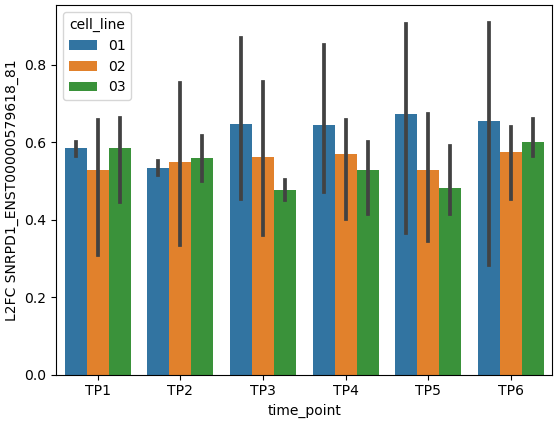

In [41]:
sdf = l2fc.loc[controls[0]].to_frame()
sdf['cell_line'] = [x.split('-')[1] for x in sdf.index]
sdf['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-1] for x in sdf.index ]
sdf['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in sdf.index ]
sdf = sdf[sdf.cell_line!='pool']
sns.barplot(data=sdf, y=controls[0], x='time_point', hue='cell_line')
pl.ylabel('L2FC SNRPD1_ENST00000579618_81')

Text(0, 0.5, 'L2FC SNRPD1_ENST00000579618_81')

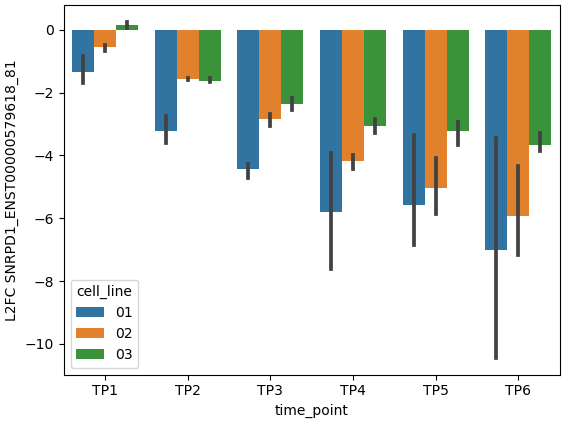

In [38]:
sdf = l2fc.loc['SNRPD1_ENST00000579618_81'].to_frame()
sdf['cell_line'] = [x.split('-')[1] for x in sdf.index]
sdf['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-1] for x in sdf.index ]
sdf['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in sdf.index ]
sdf = sdf[sdf.cell_line!='pool']
sns.barplot(data=sdf, y='SNRPD1_ENST00000579618_81', x='time_point', hue='cell_line')
pl.ylabel('L2FC SNRPD1_ENST00000579618_81')

In [33]:
sdf

,SNRPD1_ENST00000579618_81,cell_line,replicate,time_point
Sym-pool-1-1,0.077441,pool,01,Pool
Sym-pool-1-2,0.166567,pool,02,Pool
Sym-pool-1-3,0.099777,pool,03,Pool
sym-01-01-TP1,-0.819037,01,01,TP1
sym-01-01-TP2,-2.736877,01,01,TP2
sym-01-01-TP3,-4.335904,01,01,TP3
sym-01-01-TP4,-5.856850,01,01,TP4
sym-01-01-TP5,-6.548236,01,01,TP5
sym-01-01-TP6,-10.443980,01,01,TP6
sym-01-02-TP1,-1.554343,01,02,TP1


# Log Fold Change

In [32]:
# df = pd.read_csv(Path(config['TEMPDIR']) / 'pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)
df = pd.read_csv('/Users/peidli/work/data/SYMPHONY/pooled_screen_1/pooled_screen_1_counts.csv', index_col=0)

sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
sample_names_wo_pools = [x for x in sample_names if not any([p in x for p in pools])]
controls = [x for x in df.index if 'control' in x.lower()]

In [9]:
# change w.r.t. initial time point
# OR
# change w.r.t. pool?
# OR
# L2FC of guide counts w.r.t. NT controls?

## Against TP1

In [120]:
# First I normalize for seq-depth by bringing all NT guides to the same count
target = df.loc[controls, sample_names_wo_pools].mean().mean()
ist = df.loc[controls, sample_names_wo_pools].mean()
norm_factor = target / ist
sdf = df.loc[:, sample_names_wo_pools] * norm_factor

In [123]:
# group by sample IDs and Time
tdf = sdf.loc[:, sample_names_wo_pools].T
tdf['cell_line'] = [cell_line_dict[x.split('-')[1]] for x in tdf.index]
tdf['replicate'] = [x.split('-')[2] for x in tdf.index]
tdf['time_point'] = [x.split('-')[3].split('_')[0] for x in tdf.index]
otdf = tdf.set_index(['cell_line', 'replicate', 'time_point'])
otdf.head()

unique_guide_name               AATBC_ENST00000400385_1005  \
cell_line replicate time_point                               
H1975     01        TP1                        2012.762518   
                    TP2                        1939.812656   
                    TP3                        2048.721780   
                    TP4                        2013.386003   
                    TP5                        2182.748188   

unique_guide_name               AATBC_ENST00000400385_1562  \
cell_line replicate time_point                               
H1975     01        TP1                        2834.580428   
                    TP2                        3127.853067   
                    TP3                        2916.763182   
                    TP4                        2865.662315   
                    TP5                        2828.404023   

unique_guide_name               AATBC_ENST00000400385_1938  \
cell_line replicate time_point                               
H1975     01        TP1                        1864.871365   
                    TP2                        1964.471292   
                    TP3                        1945.709398   
                    TP4                        1945.909802   
                    TP5                        1691.957296   

unique_guide_name               AATBC_ENST00000400385_2713  \
cell_line replicate time_point                               
H1975     01        TP1                        1417.590806   
                    TP2                        1366.973586   
                    TP3                        1275.768732   
                    TP4                        1203.152553   
                    TP5                        1154.938063   

unique_guide_name               AATBC_ENST00000400385_28  \
cell_line replicate time_point                             
H1975     01        TP1                      2197.325867   
                    TP2                      2716.243537   
                    TP3                      2437.719587   
                    TP4                      2581.743227   
                    TP5                      2517.133191   

unique_guide_name               AATBC_ENST00000400385_3041  \
cell_line replicate time_point                               
H1975     01        TP1                        2447.418223   
                    TP2                        2437.411275   
                    TP3                        2569.546621   
                    TP4                        2544.890840   
                    TP5                        2440.856427   

unique_guide_name               AATBC_ENST00000400385_3400  \
cell_line replicate time_point                               
H1975     01        TP1                        2083.702177   
                    TP2                        1977.749019   
                    TP3                        1835.493353   
                    TP4                        1622.024042   
                    TP5                        1708.137216   

unique_guide_name               AATBC_ENST00000400385_3822  \
cell_line replicate time_point                               
H1975     01        TP1                        1259.479533   
                    TP2                        1184.246775   
                    TP3                        1318.270344   
                    TP4                        1367.171624   
                    TP5                        1493.175428   

unique_guide_name               AATBC_ENST00000400385_4379  \
cell_line replicate time_point                               
H1975     01        TP1                        2166.665506   
                    TP2                        2123.171741   
                    TP3                        2413.947499   
                    TP4                        2475.338450   
                    TP5                        2194.305273   

unique_guide_name               AATBC_ENST00000400385_827  ...  \
cell_line replicate time_point   

In [126]:
# FC w.r.t. TP1
ndf = (otdf / otdf.loc[:, : , 'TP1'])
ndf = ndf.reset_index(drop=True)
ndf.index = sample_names_wo_pools
fc = ndf.T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

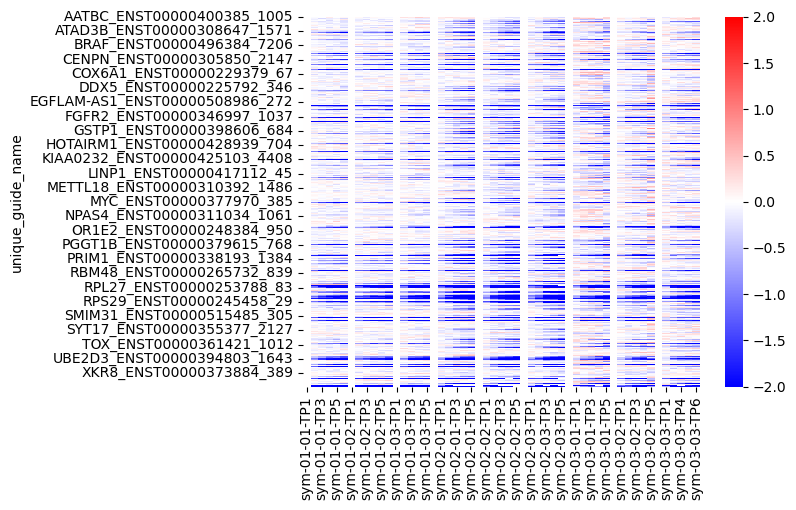

In [128]:
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

## Option 2: Against Pools

In [18]:
# Option 2, w.r.t. Pools
# Question: are the three pools in some way assignable to the samples? Like 
# should I normalize Batch1 with Pool1, otherwise I'd just use the mean over pools.
fc = (df.loc[:, sample_names].T / df.loc[:, pools].mean(axis=1)).T

<Axes: ylabel='unique_guide_name'>

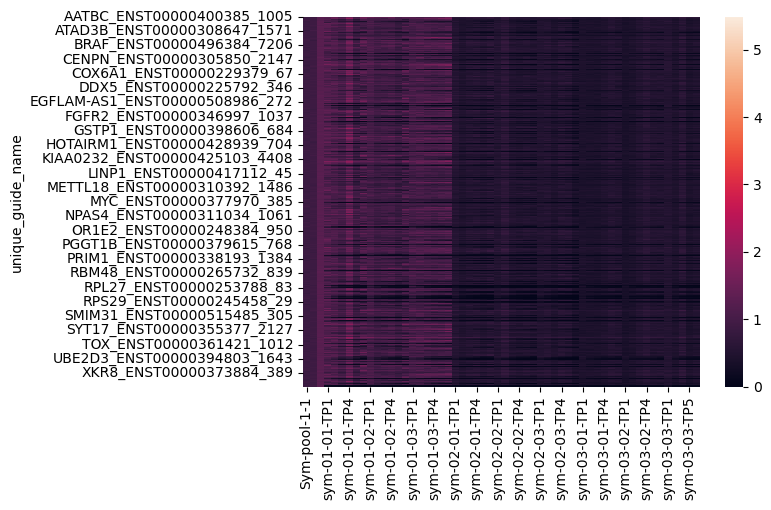

In [20]:
# The resulting FC matrix is not normalized for seq depth.
# I could normalize the NTs to the same counts, anchoring by the pools.
sns.heatmap(fc);

In [34]:
# avg NT counts in pools
df.loc[controls, pools].mean(axis=1).mean()

2771.9400000000005

In [38]:
# NT counts in samples
df.loc[controls, sample_names_wo_pools].mean(axis=0).head()

sym-01-01-TP1    2964.99
sym-01-01-TP2    2819.20
sym-01-01-TP3    2474.44
sym-01-01-TP4    3434.18
sym-01-01-TP5    2313.52
dtype: float64

In [58]:
norm_factor = df.loc[controls, pools].mean(axis=1).mean() / df.loc[controls, sample_names].mean(axis=0)

In [59]:
ndf = df.loc[:, sample_names] * norm_factor

In [60]:
# Now all NT guides have same depth / counts
ndf.loc[controls, sample_names].mean(axis=0).head()

Sym-pool-1-1     2771.94
Sym-pool-1-2     2771.94
Sym-pool-1-3     2771.94
sym-01-01-TP1    2771.94
sym-01-01-TP2    2771.94
dtype: float64

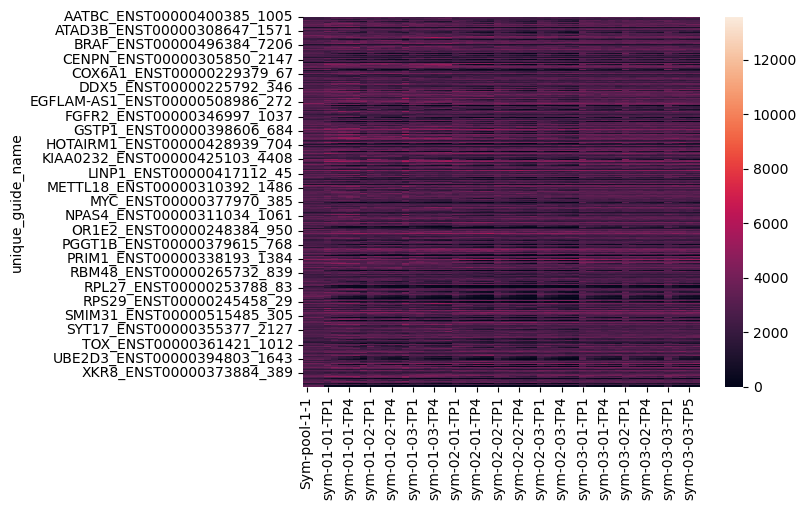

In [61]:
# after normalization
sns.heatmap(ndf);

In [74]:
# Foldchange to Pool after seq-depth normalization based on NT depth
fc = (ndf.loc[:, sample_names].T / ndf.loc[:, pools].mean(axis=1)).T
l2fc = np.log2(fc)
l2fc[l2fc==-np.infty] = None

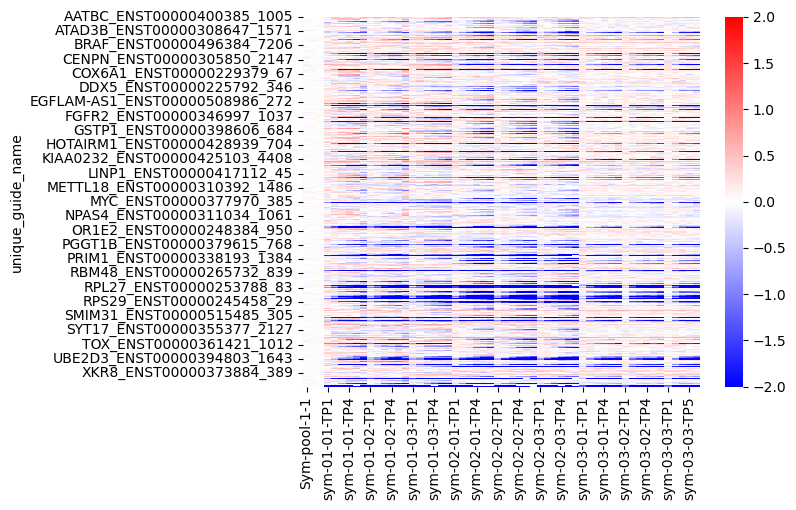

In [77]:
sns.heatmap(l2fc, cmap='bwr', center=0, vmin=-2, vmax=2); 

# Trimming

## Eval trimming

In [102]:
qcs = {x.name.split('_R1_001')[0]: pd.read_csv(x, sep='\t') for x in (Path(config['TEMPDIR']) /'pooled_screen_1/trimmed/qc').glob('*')}
df = pd.concat(qcs).droplevel(1)

In [103]:
df['fraction_filtered'] = df.Filtered_reads / df.Total_reads
df['cell_line'] = [x.split('-')[1] for x in df.index]
df['lane'] = [x.split('_')[-1] for x in df.index]
df['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in df.index ]
df['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in df.index ]

In [104]:
df.head()

,Mean_primer_distance,Mean_primer_certainty,Filtered_reads,Total_reads,fraction_filtered,cell_line,lane,replicate,time_point
sym-03-01-TP2_S40_L001,0.393326,0.186740,146127,3752185,0.038945,03,L001,01,TP2
sym-01-02-TP5_S14_L002,0.391821,0.192538,386904,7378938,0.052434,01,L002,02,TP5
sym-03-02-TP2_S41_L001,0.394498,0.185374,154890,3864224,0.040083,03,L001,02,TP2
sym-02-02-TP6_S35_L001,0.396969,0.182575,138160,3814596,0.036219,02,L001,02,TP6
sym-03-01-TP6_S52_L001,0.396831,0.182833,153899,4265629,0.036079,03,L001,01,TP6


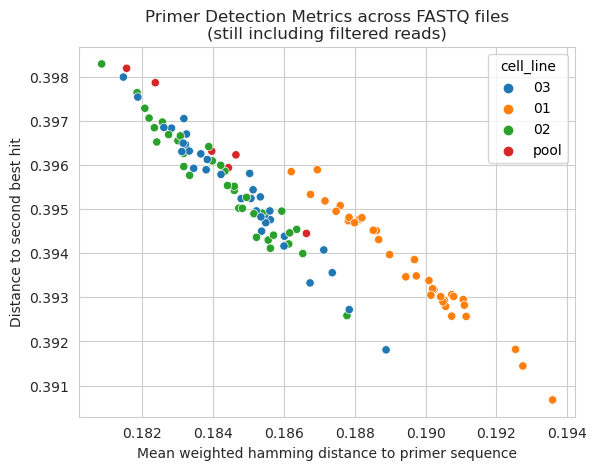

In [106]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.scatterplot(data=df, y='Mean_primer_distance', hue='cell_line', x='Mean_primer_certainty', ax=ax)
pl.xlabel('Mean weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.title('Primer Detection Metrics across FASTQ files\n(still including filtered reads)')
pl.savefig('../results/figures/trimming_qc_medians.pdf', bbox_inches='tight')
pl.show()

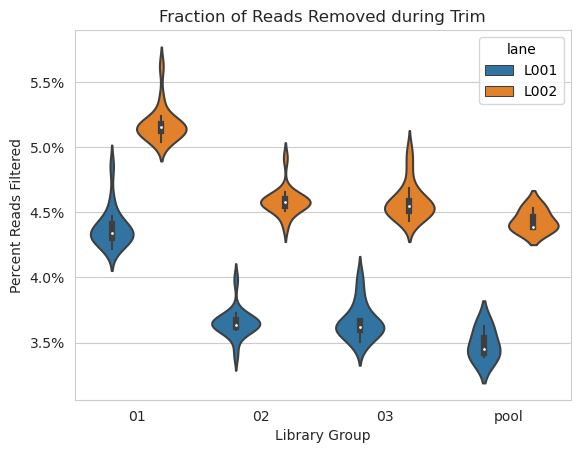

In [107]:
import matplotlib.ticker as mtick
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots()
sns.violinplot(data=df, x='cell_line', hue='lane', y='fraction_filtered', ax=ax, order=['01', '02', '03', 'pool'])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1,1))
pl.ylabel('Percent Reads Filtered')
pl.xlabel('Library Group')
pl.title('Fraction of Reads Removed during Trim')
pl.savefig('../results/figures/trimming_fraction_reads_removed.pdf', bbox_inches='tight')
pl.show()

## Finding cut-offs

In [4]:
def qual_to_float(qual):
    return list(map(ord, qual))
def make_substrings(s, K):
    return [s[i: j] for i in range(len(s)) for j in range(i + 1, len(s) + 1) if len(s[i:j]) == K]

def trim_sequence(read, quality):
    K = len(seq_primer)
    
    # search primer in expected region
    subs = make_substrings(read[pmin:pmax+K], K)
    weights = make_substrings(quality[pmin:pmax+K], K)
    primer_alignment = pd.DataFrame(index=np.arange(len(subs)), columns=['idx', 'sequence', 'hamming_distance'])
    for j, sub, w in zip(range(len(subs)), subs, weights):
        ham = hamming(list(seq_primer), list(sub), qual_to_float(w))
        primer_alignment.iloc[j] = [j+pmin, sub, ham]
    primer_alignment = primer_alignment.sort_values('hamming_distance')
    primer_idx, primer_hit, primer_distance = primer_alignment.iloc[0]
    primer_certainty = primer_alignment.hamming_distance.iloc[1] - primer_alignment.hamming_distance.iloc[0]
    
    # select guide position after primer
    trimmed_seq = read[primer_idx+K : primer_idx+K+guide_length]
    trimmed_qual = quality[primer_idx+K : primer_idx+K+guide_length]
    
    return trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty

In [5]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

In [14]:
def process(line1, line2, line3, line4):
    index = line1
    sequence = line2.replace('\n', '')
    qual = line4.replace('\n', '')

    trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
    return index, trimmed_seq, trimmed_qual

def chunker(seq, size):
    return (seq[pos:pos + size] for pos in range(0, len(seq), size))

# Parallel processing
with open(file, 'r') as INPUT:
    lines = INPUT.readlines()[:10000]  # test
    n_reads = int(len(lines) / 4)
    results = Parallel(n_jobs=4)(delayed(process)(line1, line2, line3, line4) for line1, line2, line3, line4 in tqdm(chunker(lines, size=4), total=n_reads))

# write to file
with open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    for index, trimmed_seq, trimmed_qual in tqdm(results, total=n_reads):
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')

  0%|          | 0/2500 [00:00<?, ?it/s]

  0%|          | 0/2500 [00:00<?, ?it/s]

In [9]:
# deep one
file = path / 'sym-01-01-TP1_S1_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/11277957 [00:00<?, ?it/s]

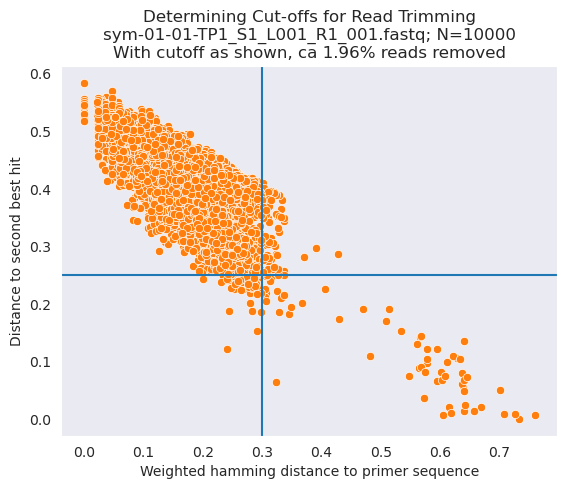

In [10]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

In [11]:
# a shallow one
file = path / 'sym-02-01-TP1_S19_L001_R1_001.fastq'

dat = []
with open(file, 'r') as INPUT, \
     open(file.with_suffix('.trimmed.fastq') , mode='w') as OUTPUT:
    lines = INPUT.readlines()
    n_reads = int(len(lines) / 4)
    for i in tqdm(range(n_reads)):
        index = lines[4*i]
        sequence = lines[4*i+1].replace('\n', '')
        # line 3 is just "+"
        qual = lines[4*i+3].replace('\n', '')
        
        trimmed_seq, trimmed_qual, primer_idx, primer_hit, primer_distance, primer_certainty = trim_sequence(sequence, qual)
        dat.append([primer_distance, primer_certainty])
        OUTPUT.write(index)
        OUTPUT.write(trimmed_seq+'\n')
        OUTPUT.write('+\n')
        OUTPUT.write(trimmed_qual+'\n')
        
        if i>10000:
            break

  0%|          | 0/5025827 [00:00<?, ?it/s]

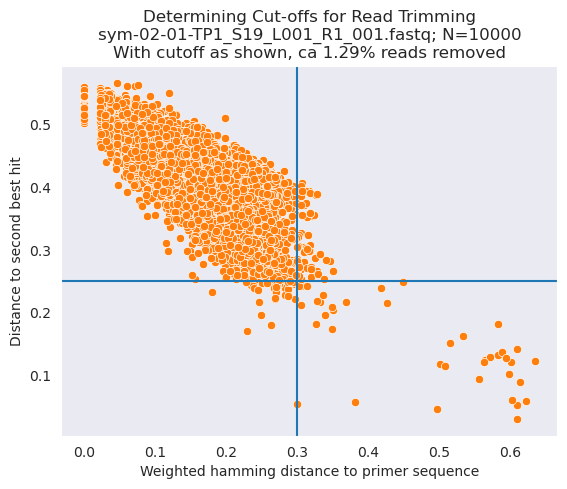

In [12]:
df = pd.DataFrame(dat, columns=['primer_distance', 'primer_certainty'])
with sns.axes_style('dark'):
    sns.scatterplot(data=df, x='primer_distance', y='primer_certainty', c='tab:orange')
xcut = 0.3
ycut = 0.25
removal = np.round(100 - 100 * len(df[(df.primer_distance < 0.3) & (df.primer_certainty > 0.25)]) / len(df), 2)
pl.axvline(xcut)
pl.axhline(ycut)
pl.title(f'Determining Cut-offs for Read Trimming\n{file.name}; N=10000\nWith cutoff as shown, ca {removal}% reads removed')
pl.xlabel('Weighted hamming distance to primer sequence')
pl.ylabel('Distance to second best hit')
pl.show()

# Evaluate guide counting /alignment

In [108]:
alignment_qc = pd.read_csv('../results/multiqc/multiqc_data/mqc_samtools_alignment_plot_1.txt', sep='\t', index_col=0)
alignment_qc['sample_id'] = [x.split('_L00')[0] for x in alignment_qc.index ]
alignment_qc = alignment_qc.groupby('sample_id').mean()  # merge lanes
alignment_qc['cell_line'] = [x.split('-')[1] for x in alignment_qc.index ]
alignment_qc['replicate'] = [x.split('-')[2] if 'pool' not in x else '0'+x[-5] for x in alignment_qc.index ]
alignment_qc['time_point'] = [x.split('-')[3][:3] if 'pool' not in x else 'Pool' for x in alignment_qc.index ]
alignment_qc['total_reads'] = alignment_qc.sum(1)
alignment_qc['fraction_mapped'] = alignment_qc['Mapped (with MQ>0)'] / alignment_qc['total_reads']
alignment_qc['cell_line_x_replicate'] = [f'{x}_{y}' for x, y in zip(alignment_qc.cell_line, alignment_qc.replicate)]

In [109]:
alignment_qc.head()

,Mapped (with MQ>0),MQ0,Unmapped,cell_line,replicate,time_point,total_reads,fraction_mapped,cell_line_x_replicate
sample_id,,,,,,,,,
Sym-pool-1-1_S55,7307104.0,16560.5,840031.0,pool,01,Pool,8163695.5,0.895073,pool_01
Sym-pool-1-2_S56,7537114.0,17022.0,869478.0,pool,02,Pool,8423614.0,0.894760,pool_02
Sym-pool-1-3_S57,10628746.5,23438.0,1195289.5,pool,03,Pool,11847474.0,0.897132,pool_03
sym-01-01-TP1_S1,9467309.0,24452.0,1199177.0,01,01,TP1,10690938.0,0.885545,01_01
sym-01-01-TP2_S4,8729523.5,22547.0,1078519.5,01,01,TP2,9830590.0,0.887996,01_01


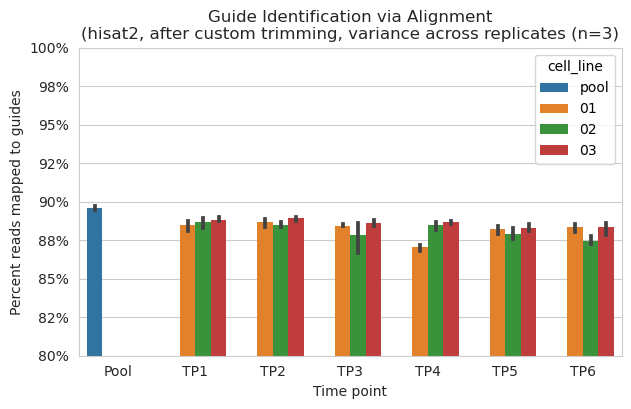

In [110]:
with sns.axes_style('whitegrid'):
    fig, ax = pl.subplots(figsize=(7,4))
sns.barplot(data=alignment_qc.reset_index(), x='time_point', y='fraction_mapped', ax=ax, hue='cell_line', dodge=True)
import matplotlib.ticker as mtick
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, 0))
ax.set_ylim([0.8,1])
ax.set_ylabel('Percent reads mapped to guides')
ax.set_xlabel('Time point')
ax.set_title('Guide Identification via Alignment\n(hisat2, after custom trimming, variance across replicates (n=3)')
pl.savefig('../results/figures/guide_alignment_qc_mapping.pdf', bbox_inches='tight')
pl.show()